In [ ]:
from __future__ import annotations
import operator
import re
from typing import TypedDict,List,Annotated,Literal
from pydantic import BaseModel,Field
from langgraph.graph import StateGraph,START,END
from langgraph.types import Send
from langchain_groq import ChatGroq
from langchain.messages import SystemMessage,HumanMessage
from dotenv import load_dotenv
load_dotenv()

#*******************Main Code*****************************************

class Task(BaseModel):
    id:int
    title:str
    goal:str=Field(description="What the reader should understand after this section")
    bullets:List[str]=Field(description="3-5 concrete subpoints",min_length=3,max_length=5)
    target_words:int=Field(description="Target word count",ge=120,le=450)
    section_type:Literal["intro","core","examples","checklist","common_mistakes","conclusion"]
    brief:str=Field(description='What to cover')

class Plan(BaseModel):
    blog_title:str
    audience:str
    tone:str
    tasks:List[Task]=Field(min_length=5,max_length=7)

class SectionResult(TypedDict):
    id:int
    content:str

class State(TypedDict):
    topic:str
    plan:Plan
    #reducer    : results from  workers get concatenated 
    sections:Annotated[List[SectionResult],operator.add]
    final:str


llm=ChatGroq(model="openai/gpt-oss-120b")

def orchestator(state:State)->dict:
    plan=llm.with_structured_output(Plan).invoke([
        SystemMessage(content=('''Create a blog plan of 5-7 sections on thr following  topic.''')
        ),HumanMessage(content=f"Topic:{state['topic']}")
    ])
    return {"plan":plan}


#intermidate function that will create  multiple workers AS per story 
def fanout(state: State):
    return [
        Send("worker", {
            "task": task,
            "topic": state['topic'],
            "plan": state['plan']
        })
        for task in state['plan'].tasks
    ]

def worker(payload:dict)->dict:
    #payload contains what we want to sent
    task=payload['task']
    topic=payload['topic']
    plan=payload['plan']

    bullets_text="\n".join(f"{index}. {bullet}" for index,bullet in enumerate(task.bullets,start=1))
    section_md=llm.invoke([
        SystemMessage(content="Write One clear markdown section"),
        HumanMessage(
            content=(f"Blog:{plan.blog_title}\n" 
                    f"Topic:{topic}\n\n"
                    f"Section:{task.title}\n"
                    f"Goal:{task.goal}\n"
                    f"Target words:{task.target_words}\n"
                    f"Bullets:{bullets_text}\n"
                    f"Brief:{task.brief}\n\n"
                    "Return only the section  content  in Markdown."),
            )
        ]
    ).content.strip()

    return{"sections":[{"id":task.id,"content":section_md}]}


#reducer code sitch the whole blog
from pathlib import Path
def reducer(state:State)->dict:
    title=state['plan'].blog_title
    ordered_sections=sorted(state['sections'],key=lambda section:section['id'])
    body="\n\n".join(section['content'] for section in ordered_sections).strip()

    final_md=f'#{title}\n\n{body}\n'


    #------save the file-----------
    filename=re.sub(r"[^A-Za-z0-9_-]+","_",title.strip()).strip("_").lower()+ ".md"
    output_path=Path(filename)
    output_path.write_text(final_md,encoding="utf-8")

    return {"final":final_md}


g=StateGraph(State)
g.add_node("orchestator",orchestator)
g.add_node("worker",worker)
g.add_node("reducer",reducer)

g.add_edge(START,"orchestator")
g.add_conditional_edges("orchestator",fanout)
g.add_edge("worker","reducer")
g.add_edge("reducer",END)

app=g.compile()

out=app.invoke({"topic":"write a blog on usuage of mobile phone increasing day by day ","sections":[]})
print(out["final"])

#The Growing Grip: How Mobile Phone Usage Is Escalating Every Day

## Introduction – A Digital Phenomenon  

The past decade has witnessed an unprecedented surge in mobile phone ownership. From bustling megacities to remote villages, smartphones now outnumber the world’s population, with **over 7 billion devices active today**—a figure that continues to climb as affordable models and expanding network coverage bring connectivity to previously unreachable corners.  

Why does this matter?  

- **Individuals** experience a reshaping of daily routines, from how they consume news to how they manage health, work, and social relationships. Understanding usage patterns helps people strike a healthier balance between screen time and offline life.  
- **Businesses** rely on mobile data to tailor marketing, optimize app experiences, and forecast demand. Real‑time insights into how, when, and where users engage with their devices drive revenue and innovation.  
- **Policymakers** need accurate us

#The Daily Surge: How Mobile Phone Usage Is Growing Every Day

## Introduction – The Ubiquity of Mobile Phones

In just a few short decades, the mobile phone has transformed from a luxury gadget into an indispensable extension of daily life. Today, a typical adult checks their device dozens of times a day—whether to send a quick text, scroll through social media, navigate a commute, or manage work tasks on the go. This constant connectivity reshapes how we communicate, consume information, and even think.

Tracking mobile‑phone usage trends isn’t just a curiosity; it’s a vital lens for understanding broader societal shifts. Rising screen time can signal changes in consumer behavior, highlight emerging opportunities (and challenges) for businesses, and reveal the impact of technology on mental health, productivity, and social interaction. By monitoring these patterns, policymakers, marketers, and individuals alike can make more informed decisions about the role of mobile technology in o

# BLog Simple but better prompting 

In [16]:
from __future__ import annotations
import operator
from typing import TypedDict,List,Annotated,Literal
from pydantic import BaseModel,Field
from langgraph.graph import StateGraph,START,END
from langgraph.types import Send
from langchain_groq import ChatGroq
from langchain.messages import SystemMessage,HumanMessage
from dotenv import load_dotenv
load_dotenv()

#*******************Main Code*****************************************
class Task(BaseModel):
    id:int
    title:str

    goal:str=Field(
        description="One sentence  describing  what the  reader  should be  able to/do understand  after this section."
    )
    bullets:List[str]=Field(description="3-5 concrete,non overlapping subpoints  to cover  in this  section ",
                            min_length=3,
                            max_length=5,
                            )
    target_words:int=Field(description="Target word  count for  this section (120-450)")
    section_type:Literal[
        "intro","core","examples","checklist","common_mistakes","conclusion"
    ]=Field(description="use common_mistakes once  in the plan ")
    

class Plan(BaseModel):
    Blog_title:str
    audience:str=Field(description="Who is the blog for .")
    tone:str=Field(description="Writing tone (e.g.., practical,crisp)")
    tasks:List[Task]



class State(TypedDict):
    topic:str
    plan:Plan
    #reducer    : results from  workers get concatenated 
    sections:Annotated[List[str],operator.add]
    final:str


llm=ChatGroq(model="openai/gpt-oss-120b")

def orchestator(state:State)->dict:
    plan=llm.with_structured_output(Plan).invoke([
        SystemMessage(content=('''You are a senior technical writer and developer advocate. Your job is to produce a 
        "highly actionable outline for a technical blog post.\n\n"    "Hard requirements:\n"
        "- Create 5–7 sections (tasks) that fit a technical blog.\n"
        "- Each section must include:\n"
        "  1) goal (1 sentence: what the reader can do/understand after the section)\n"
        "  2) 3–5 bullets that are concrete, specific, and non-overlapping\n"
         "  3) target word count (120–450)\n"
        "- Include EXACTLY ONE section with section_type='common_mistakes'.\n\n"
        "Make it technical (not generic):\n"
        "- Assume the reader is a developer; use correct terminology.\n"
        "- Prefer design/engineering structure: problem → intuition → approach → implementation → "
        "trade-offs → testing/observability → conclusion.\n"
        "- Bullets must be actionable and testable (e.g., 'Show a minimal code snippet for X', "
        "'Explain why Y fails under Z condition', 'Add a checklist for production readiness').\n"
        "- Explicitly include at least ONE of the following somewhere in the plan (as bullets):\n"
        "  * a minimal working example (MWE) or code sketch\n"
        "  * edge cases / failure modes\n"
        "  * performance/cost considerations\n"
        "  * security/privacy considerations (if relevant)\n"
        "  * debugging tips / observability (logs, metrics, traces)\n"
        "- Avoid vague bullets like 'Explain X' or 'Discuss Y'. Every bullet should state what "
        "to build/compare/measure/verify.\n\n"
        "Ordering guidance:\n"
        "- Start with a crisp intro and problem framing.\n"
        "- Build core concepts before advanced details.\n"
        "- Include one section for common mistakes and how to avoid them.\n"
        "- End with a practical summary/checklist and next steps.\n\n"
        "Output must strictly match the Plan schema.
''')
        ),HumanMessage(content=f"Topic:{state['topic']}")
    ])
    return {"plan":plan}


#intermidate function that will create  multiple workers AS per story 
def fanout(state: State):
    return [
        Send("worker", {
            "task": task,
            "topic": state['topic'],
            "plan": state['plan']
        })
        for task in state['plan'].tasks
    ]

def worker(payload:dict)->dict:
    #payload contains what we want to sent
    task=payload['task']
    topic=payload['topic']
    plan=payload['plan']
    bullets_text = "\n".join(
    f"- {bullet}" for bullet in task.bullets
)

    blog_title=plan.Blog_title
    section_md=llm.invoke([
        SystemMessage(content="You are a senior technical writer and developer advocate. Write ONE section of a technical blog post in Markdown.\n\n"
        "Hard constraints:\n"
        "- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).\n"
        "- Stay close to the Target words (±15%).\n"
        "- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).\n\n"
        "Technical quality bar:\n"
        "- Be precise and implementation-oriented (developers should be able to apply it).\n"
        "- Prefer concrete details over abstractions: APIs, data structures, protocols, and exact terms.\n"
        "- When relevant, include at least one of:\n"
        "  * a small code snippet (minimal, correct, and idiomatic)\n"
        "  * a tiny example input/output\n"
        "  * a checklist of steps\n"
        "  * a diagram described in text (e.g., 'Flow: A -> B -> C')\n"
        "- Explain trade-offs briefly (performance, cost, complexity, reliability).\n"
        "- Call out edge cases / failure modes and what to do about them.\n"
        "- If you mention a best practice, add the 'why' in one sentence.\n\n"
        "Markdown style:\n"
        "- Start with a '##  <Section Title>' heading.\n"
        "- Use short paragraphs, bullet lists where helpful, and code fences for code.\n"
        "- Avoid fluff. Avoid marketing language.\n"
        "- If you include code, keep it focused on the bullet being addressed.\n"),
        HumanMessage(
            content=(f"Blog: {plan.Blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Section type: {task.section_type}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Bullets:{bullets_text}\n"
                    "Return only the section  content  in Markdown."),
            )
        ]
    ).content.strip()

    return{"sections":[section_md]}


#reducer code sitch the whole blog
from pathlib import Path
def reducer(state:State)->dict:
    title=state['plan'].Blog_title
    body="\n\n".join(state['sections']).strip()

    final_md=f'#{title}\n\n{body}\n'


    #------save the file-----------
    filename=title.lower().replace(" ","_")+ ".md"
    output_path=Path(filename)
    output_path.write_text(final_md,encoding="utf-8")

    return {"final":final_md}


g=StateGraph(State)
g.add_node("orchestator",orchestator)
g.add_node("worker",worker)
g.add_node("reducer",reducer)

g.add_edge(START,"orchestator")
g.add_conditional_edges("orchestator",fanout)
g.add_edge("worker","reducer")
g.add_edge("reducer",END)

app=g.compile()

out=app.invoke({"topic":"Transformer ","sections":[]})

# BLOG THAT RESEARCH

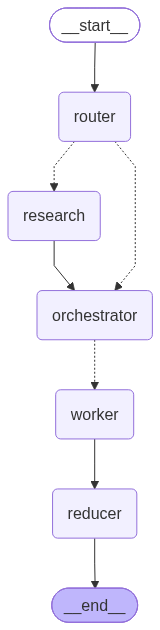

In [17]:
from __future__ import annotations

import operator
from pathlib import Path
from typing import TypedDict, List, Optional, Literal, Annotated

from pydantic import BaseModel, Field
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send


from langchain_core.messages import SystemMessage, HumanMessage
from langchain_community.tools.tavily_search import TavilySearchResults
# -----------------------------
# 1) Schemas
# -----------------------------
class Task(BaseModel):
    id: int
    title: str

    goal: str = Field(
        ...,
        description="One sentence describing what the reader should be able to do/understand after this section.",
    )
    bullets: List[str] = Field(
        ...,
        min_length=3,
        max_length=6,
        description="3–6 concrete, non-overlapping subpoints to cover in this section.",
    )
    target_words: int = Field(..., description="Target word count for this section (120–550).")

    tags: List[str] = Field(default_factory=list)
    requires_research: bool = False
    requires_citations: bool = False
    requires_code: bool = False


class Plan(BaseModel):
    blog_title: str
    audience: str
    tone: str
    blog_kind: Literal["explainer", "tutorial", "news_roundup", "comparison", "system_design"] = "explainer"
    constraints: List[str] = Field(default_factory=list)
    tasks: List[Task]


class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None  # keep if Tavily provides; DO NOT rely on it
    snippet: Optional[str] = None
    source: Optional[str] = None


class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list)


class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)
class State(TypedDict):
    topic: str

    # routing / research
    mode: str
    needs_research: bool
    queries: List[str]
    evidence: List[EvidenceItem]
    plan: Optional[Plan]

    # workers
    sections: Annotated[List[tuple[int, str]], operator.add]  # (task_id, section_md)
    final: str
# -----------------------------
# 2) LLM
# -----------------------------
llm = ChatGroq(model='openai/gpt-oss-120b')
# -----------------------------
# 3) Router (decide upfront)
# -----------------------------
ROUTER_SYSTEM = """You are a routing module for a technical blog planner.

Decide whether web research is needed BEFORE planning.

Modes:
- closed_book (needs_research=false):
  Evergreen topics where correctness does not depend on recent facts (concepts, fundamentals).
- hybrid (needs_research=true):
  Mostly evergreen but needs up-to-date examples/tools/models to be useful.
- open_book (needs_research=true):
  Mostly volatile: weekly roundups, "this week", "latest", rankings, pricing, policy/regulation.

If needs_research=true:
- Output 3–10 high-signal queries.
- Queries should be scoped and specific (avoid generic queries like just "AI" or "LLM").
- If user asked for "last week/this week/latest", reflect that constraint IN THE QUERIES.
"""

def router_node(state: State) -> dict:
    
    topic = state["topic"]
    decider = llm.with_structured_output(RouterDecision)
    decision = decider.invoke(
        [
            SystemMessage(content=ROUTER_SYSTEM),
            HumanMessage(content=f"Topic: {topic}"),
        ]
    )

    return {
        "needs_research": decision.needs_research,
        "mode": decision.mode,
        "queries": decision.queries,
    }

def route_next(state: State) -> str:
    return "research" if state["needs_research"] else "orchestrator"
# -----------------------------
# 4) Research (Tavily) 
# -----------------------------
def _tavily_search(query: str, max_results: int = 5) -> List[dict]:
    
    tool = TavilySearchResults(max_results=max_results)
    results = tool.invoke({"query": query})

    normalized: List[dict] = []
    for r in results or []:
        normalized.append(
            {
                "title": r.get("title") or "",
                "url": r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                "published_at": r.get("published_date") or r.get("published_at"),
                "source": r.get("source"),
            }
        )
    return normalized


RESEARCH_SYSTEM = """You are a research synthesizer for technical writing.

Given raw web search results, produce a deduplicated list of EvidenceItem objects.

Rules:
- Only include items with a non-empty url.
- Prefer relevant + authoritative sources (company blogs, docs, reputable outlets).
- If a published date is explicitly present in the result payload, keep it as YYYY-MM-DD.
  If missing or unclear, set published_at=null. Do NOT guess.
- Keep snippets short.
- Deduplicate by URL.
"""

def research_node(state: State) -> dict:

    # take the first 10 queries from state
    queries = (state.get("queries", []) or [])
    max_results = 6

    raw_results: List[dict] = []

    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    if not raw_results:
        return {"evidence": []}

    extractor = llm.with_structured_output(EvidencePack)
    pack = extractor.invoke(
        [
            SystemMessage(content=RESEARCH_SYSTEM),
            HumanMessage(content=f"Raw results:\n{raw_results}"),
        ]
    )

    # Deduplicate by URL
    dedup = {}
    for e in pack.evidence:
        if e.url:
            dedup[e.url] = e

    return {"evidence": list(dedup.values())}
# -----------------------------
# 5) Orchestrator (Plan)
# -----------------------------
ORCH_SYSTEM = """You are a senior technical writer and developer advocate.
Your job is to produce a highly actionable outline for a technical blog post.

Hard requirements:
- Create 5–9 sections (tasks) suitable for the topic and audience.
- Each task must include:
  1) goal (1 sentence)
  2) 3–6 bullets that are concrete, specific, and non-overlapping
  3) target word count (120–550)

Quality bar:
- Assume the reader is a developer; use correct terminology.
- Bullets must be actionable: build/compare/measure/verify/debug.
- Ensure the overall plan includes at least 2 of these somewhere:
  * minimal code sketch / MWE (set requires_code=True for that section)
  * edge cases / failure modes
  * performance/cost considerations
  * security/privacy considerations (if relevant)
  * debugging/observability tips

Grounding rules:
- Mode closed_book: keep it evergreen; do not depend on evidence.
- Mode hybrid:
  - Use evidence for up-to-date examples (models/tools/releases) in bullets.
  - Mark sections using fresh info as requires_research=True and requires_citations=True.
- Mode open_book:
  - Set blog_kind = "news_roundup".
  - Every section is about summarizing events + implications.
  - DO NOT include tutorial/how-to sections unless user explicitly asked for that.
  - If evidence is empty or insufficient, create a plan that transparently says "insufficient sources"
    and includes only what can be supported.

Output must strictly match the Plan schema.
"""

def orchestrator_node(state: State) -> dict:
    planner = llm.with_structured_output(Plan)

    evidence = state.get("evidence", [])
    mode = state.get("mode", "closed_book")

    plan = planner.invoke(
        [
            SystemMessage(content=ORCH_SYSTEM),
            HumanMessage(
                content=(
                    f"Topic: {state['topic']}\n"
                    f"Mode: {mode}\n\n"
                    f"Evidence (ONLY use for fresh claims; may be empty):\n"
                    f"{[e.model_dump() for e in evidence][:16]}"
                )
            ),
        ]
    )

    return {"plan": plan}
# -----------------------------
# 6) Fanout
# -----------------------------
def fanout(state: State):
    return [
        Send(
            "worker",
            {
                "task": task.model_dump(),
                "topic": state["topic"],
                "mode": state["mode"],
                "plan": state["plan"].model_dump(),
                "evidence": [e.model_dump() for e in state.get("evidence", [])],
            },
        )
        for task in state["plan"].tasks
    ]
# -----------------------------
# 7) Worker (write one section)
# -----------------------------
WORKER_SYSTEM = """You are a senior technical writer and developer advocate.
Write ONE section of a technical blog post in Markdown.

Hard constraints:
- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).
- Stay close to Target words (±15%).
- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).
- Start with a '## <Section Title>' heading.

Scope guard:
- If blog_kind == "news_roundup": do NOT turn this into a tutorial/how-to guide.
  Do NOT teach web scraping, RSS, automation, or "how to fetch news" unless bullets explicitly ask for it.
  Focus on summarizing events and implications.

Grounding policy:
- If mode == open_book:
  - Do NOT introduce any specific event/company/model/funding/policy claim unless it is supported by provided Evidence URLs.
  - For each event claim, attach a source as a Markdown link: ([Source](URL)).
  - Only use URLs provided in Evidence. If not supported, write: "Not found in provided sources."
- If requires_citations == true:
  - For outside-world claims, cite Evidence URLs the same way.
- Evergreen reasoning is OK without citations unless requires_citations is true.

Code:
- If requires_code == true, include at least one minimal, correct code snippet relevant to the bullets.

Style:
- Short paragraphs, bullets where helpful, code fences for code.
- Avoid fluff/marketing. Be precise and implementation-oriented.
"""

def worker_node(payload: dict) -> dict:
    
    task = Task(**payload["task"])
    plan = Plan(**payload["plan"])
    evidence = [EvidenceItem(**e) for e in payload.get("evidence", [])]
    topic = payload["topic"]
    mode = payload.get("mode", "closed_book")

    bullets_text = "\n- " + "\n- ".join(task.bullets)

    evidence_text = ""
    if evidence:
        evidence_text = "\n".join(
            f"- {e.title} | {e.url} | {e.published_at or 'date:unknown'}".strip()
            for e in evidence[:20]
        )

    section_md = llm.invoke(
        [
            SystemMessage(content=WORKER_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog title: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Constraints: {plan.constraints}\n"
                    f"Topic: {topic}\n"
                    f"Mode: {mode}\n\n"
                    f"Section title: {task.title}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Tags: {task.tags}\n"
                    f"requires_research: {task.requires_research}\n"
                    f"requires_citations: {task.requires_citations}\n"
                    f"requires_code: {task.requires_code}\n"
                    f"Bullets:{bullets_text}\n\n"
                    f"Evidence (ONLY use these URLs when citing):\n{evidence_text}\n"
                )
            ),
        ]
    ).content.strip()

    return {"sections": [(task.id, section_md)]}
# -----------------------------
# 8) Reducer (merge + save)
# -----------------------------
def reducer_node(state: State) -> dict:

    plan = state["plan"]

    ordered_sections = [md for _, md in sorted(state["sections"], key=lambda x: x[0])]
    body = "\n\n".join(ordered_sections).strip()
    final_md = f"# {plan.blog_title}\n\n{body}\n"

    filename = f"{plan.blog_title}.md"
    Path(filename).write_text(final_md, encoding="utf-8")

    return {"final": final_md}
# -----------------------------
# 9) Build graph
# -----------------------------
g = StateGraph(State)
g.add_node("router", router_node)
g.add_node("research", research_node)
g.add_node("orchestrator", orchestrator_node)
g.add_node("worker", worker_node)
g.add_node("reducer", reducer_node)

g.add_edge(START, "router")
g.add_conditional_edges("router", route_next, {"research": "research", "orchestrator": "orchestrator"})
g.add_edge("research", "orchestrator")

g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()
app

In [18]:
# -----------------------------
# 10) Runner
# -----------------------------
def run(topic: str):
    out = app.invoke(
        {
            "topic": topic,
            "mode": "",
            "needs_research": False,
            "queries": [],
            "evidence": [],
            "plan": None,
            "sections": [],
            "final": "",
        }
    )

    return out
#run("Write a blog on Open Source LLMs in 2026")
run("State of Multimodal LLMs in 2026")

APIStatusError: Error code: 413 - {'error': {'message': 'Request too large for model `openai/gpt-oss-120b` in organization `org_01krperge8f2nvwvvj926chze6` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Requested 29050, please reduce your message size and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}